In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

In [2]:
data = pd.read_table('p176.txt')

In [9]:
data.head()

,X,Y
0,294,30
1,247,32
2,267,37
3,358,44
4,423,47


In [3]:
x = data['X']
y = data['Y']

In [14]:
np.sum(x*y)

np.int64(2323945)

In [15]:
np.sum(x*x)

np.int64(19245812)

In [4]:
n = data.shape[0]
print(n)

27


In [5]:
B1 = ((n*(np.sum(x*y)))-(np.sum(x)*np.sum(y)))/((n*np.sum(x*x))-(np.sum(x)*np.sum(x)))
print(B1)

0.10536109357806465


In [6]:
B0 = (1/n)*((np.sum(y))-(B1*np.sum(x)))
print(B0)

14.448058579617584


Linear Regression Equation is Y = 0.105 + 14.448 * X
X = 156

In [13]:
Y = 14.448058579617584 + 0.10536109357806465 * 156
print(Y)

30.88438917779567


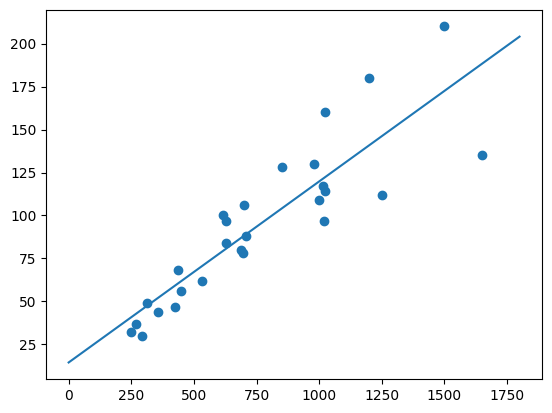

In [15]:
plt.scatter(x,y)
x1=np.linspace(0,1800,500)
y1=B0+B1*x1
plt.plot(x1,y1,'-')
plt.show()

In [8]:
X=pd.read_csv('LR_X.csv')
Y=pd.read_csv('LR_Y.csv')

In [12]:
X.shape

(1000, 3)

In [10]:
Y.shape

(1000, 1)

In [24]:
X.head()

,X1,X2,X3
0,0.26,0.08,0.28
1,0.26,0.52,0.01
2,0.85,0.60,0.14
3,0.94,0.22,0.48
4,0.53,0.05,0.76


In [25]:
Y.head()

,Y
0,1.472
1,1.802
2,1.548
3,1.390
4,2.141


In [26]:
X.describe()

,X1,X2,X3
count,1000.000000,1000.000000,1000.000000
mean,0.493360,0.501480,0.493320
std,0.287477,0.287708,0.285183
min,0.000000,0.000000,0.000000
25%,0.250000,0.270000,0.250000
50%,0.480000,0.495000,0.490000
75%,0.740000,0.750000,0.730000
max,1.000000,1.000000,1.000000


In [27]:
Y.describe()

,Y
count,1000.000000
mean,2.546380
std,0.923232
min,0.089000
25%,1.833250
50%,2.587000
75%,3.206250
max,5.018000


In [14]:
ones=np.ones((1000,1))

In [29]:
ones.shape

(1000, 1)

B = (X^T X)^-1 X^T Y

In [23]:
new_X=np.concatenate((ones,X),axis=1)

In [24]:
new_X

array([[1.  , 0.26, 0.08, 0.28],
       [1.  , 0.26, 0.52, 0.01],
       [1.  , 0.85, 0.6 , 0.14],
       ...,
       [1.  , 0.88, 0.06, 0.33],
       [1.  , 0.28, 0.4 , 0.41],
       [1.  , 0.94, 0.48, 0.45]], shape=(1000, 4))

In [25]:
new_X.shape

(1000, 4)

In [29]:
res1=np.linalg.inv(np.dot(np.transpose(new_X),new_X))
res1.shape

(4, 4)

In [28]:
res2=np.dot(np.transpose(new_X),Y)
res2.shape

(4, 1)

In [30]:
beta=np.dot(res1,res2)
print(beta)

[[ 1. ]
 [-1.2]
 [ 2.1]
 [ 2.2]]


The equation of the linear regression is Y=1.0-1.2x1+2.1x2+2.2*x2

In [32]:
x

0      294
1      247
2      267
3      358
4      423
5      311
6      450
7      534
8      438
9      697
10     688
11     630
12     709
13     627
14     615
15     999
16    1022
17    1015
18     700
19     850
20     980
21    1025
22    1021
23    1200
24    1250
25    1500
26    1650
Name: X, dtype: int64

In [33]:
y

0      30
1      32
2      37
3      44
4      47
5      49
6      56
7      62
8      68
9      78
10     80
11     84
12     88
13     97
14    100
15    109
16    114
17    117
18    106
19    128
20    130
21    160
22     97
23    180
24    112
25    210
26    135
Name: Y, dtype: int64

In [34]:
data

,X,Y
0,294,30
1,247,32
2,267,37
3,358,44
4,423,47
5,311,49
6,450,56
7,534,62
8,438,68
9,697,78


In [35]:
x=data['X']
y=data['Y']

In [36]:
x1=(x-np.mean(x))/np.std(x)
y1=(y-np.mean(y))/np.std(y)

In [37]:
def grad_beta0(beta0,beta1,x1,y1):
    n=len(x1)
    res=0
    for i in range(n):
        res+=(y1[i]-beta0-beta1*x1[i])
    grad_b0=-2/float(n)*res
    #print(grad_b0)
    return grad_b0

In [43]:
def grad_beta1(beta0,beta1,x1,y1):
    n=len(x1)
    res=0
    for i in range(n):
        res+=x1[i]*(y1[i]-beta0-beta1*x1[i])
    grad_b1=-2/float(n)*res
    return grad_b1

In [39]:
def gradient_descent(x,y):
    beta0=0
    beta1=0
    lr=0.1
    epochs=1
    while epochs<=100:
        up_b0=grad_beta0(beta0,beta1,x1,y1)
        up_b1=grad_beta1(beta0,beta1,x1,y1)
        beta0=beta0-lr*up_b0
        beta1=beta1-lr*up_b1
        y_hat=beta0+beta1*x
        plt.plot(x,y_hat)
        epochs+=1
    return beta0,beta1

-5.468876380560958e-17 0.8808360812820623


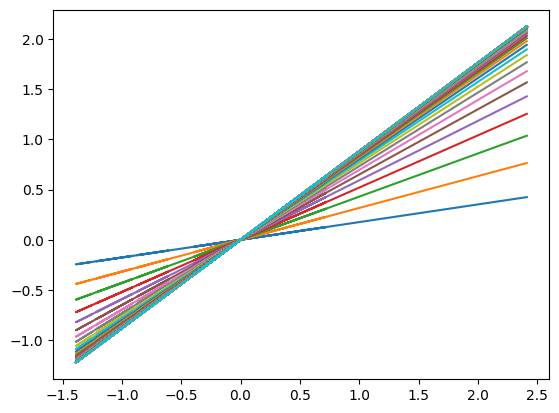

In [40]:
b0,b1=gradient_descent(x1,y1)
print(b0,b1)